# Churn em telecom: quem deve receber a oferta de retenção?

**Júlia Muniz Carvalho** · Ciência da Computação (UFABC) · [GitHub do projeto](https://github.com/juliamunizcarvalh0/previsao-churn)

A maioria dos notebooks sobre este dataset para na acurácia. Aqui a pergunta é de negócio: **se cada oferta de retenção custa dinheiro, para quais clientes vale a pena oferecer?**

O caminho:
1. Entender e limpar os dados (há uma armadilha em `TotalCharges`).
2. Comparar um modelo simples e um complexo com validação cruzada.
3. Escolher o limiar de decisão que **maximiza o lucro** da campanha, e não o padrão de 0,5.
4. Avaliar tudo num conjunto de teste que não foi usado em nenhuma decisão.

O mesmo código, com API FastAPI, testes e Docker, está no [repositório do GitHub](https://github.com/juliamunizcarvalh0/previsao-churn).

In [1]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False})
AZUL, VERMELHO = "#2563eb", "#dc2626"

## 1. Dados

Dataset *Telco Customer Churn*, publicado pela IBM: 7.043 clientes de uma operadora fictícia da Califórnia, com valores em dólar. No Kaggle, basta adicionar o dataset `blastchar/telco-customer-churn` ao notebook; fora dele, o CSV é baixado do repositório oficial da IBM.

In [2]:
kaggle_csv = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True)
fonte = kaggle_csv[0] if kaggle_csv else (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)
raw = pd.read_csv(fonte)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### A armadilha do `TotalCharges`

A coluna parece numérica, mas vem como texto. O motivo: 11 clientes têm o campo em branco. Todos têm `tenure = 0`, ou seja, acabaram de assinar e ainda não pagaram nenhuma fatura. O valor correto para eles é **0**, e não a média nem a remoção da linha.

In [3]:
em_branco = raw["TotalCharges"].astype(str).str.strip() == ""
print("TotalCharges em branco:", em_branco.sum())
print("tenure desses clientes:", raw.loc[em_branco, "tenure"].unique())

df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(),
                                   errors="coerce").fillna(0.0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(f"Taxa de churn: {df['Churn'].mean():.1%}")

TotalCharges em branco: 11
tenure desses clientes: [0]
Taxa de churn: 26.5%


## 2. O que os dados mostram

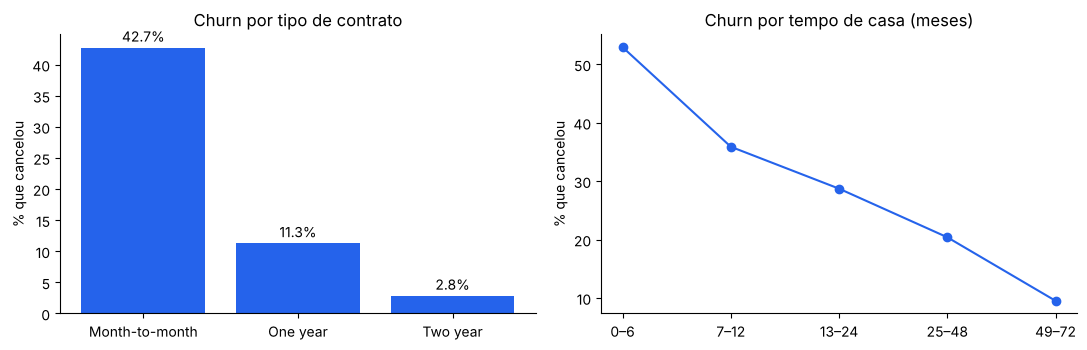

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
taxa = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
axes[0].bar(taxa.index, taxa.values * 100, color=AZUL)
axes[0].set_title("Churn por tipo de contrato")
axes[0].set_ylabel("% que cancelou")
for i, v in enumerate(taxa.values):
    axes[0].text(i, v * 100 + 1, f"{v:.1%}", ha="center")

faixas = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
taxa_t = df.groupby(faixas, observed=True)["Churn"].mean()
axes[1].plot(taxa_t.index.astype(str), taxa_t.values * 100, marker="o", color=AZUL)
axes[1].set_title("Churn por tempo de casa (meses)")
axes[1].set_ylabel("% que cancelou")
plt.tight_layout()
plt.show()

In [5]:
(df.groupby("PaymentMethod")["Churn"].agg(["mean", "size"])
   .rename(columns={"mean": "taxa_churn", "size": "clientes"})
   .sort_values("taxa_churn", ascending=False)
   .style.format({"taxa_churn": "{:.1%}"}))

,taxa_churn,clientes
PaymentMethod,,
Electronic check,45.3%,2365
Mailed check,19.1%,1612
Bank transfer (automatic),16.7%,1544
Credit card (automatic),15.2%,1522


**Leitura:** o cancelamento se concentra nos primeiros meses e nos contratos mensais (42,7%, contra 2,8% nos contratos de dois anos). O pagamento por *electronic check* também se destaca, com cerca de 45% de churn. São sinais fortes, então um modelo simples já deve ir bem.

## 3. Modelos

Separo 20% dos clientes como **teste** antes de qualquer decisão. No treino, comparo dois modelos com validação cruzada de 5 dobras:

- **Regressão logística**, simples e interpretável;
- **Gradient boosting**, mais flexível.

Regra de escolha, definida antes de ver os números: o modelo complexo só substitui o simples se ganhar **mais de 0,005** de ROC-AUC. Complexidade tem custo de manutenção e de explicação.

In [6]:
NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
BIN = ["SeniorCitizen"]
CAT = [c for c in df.columns if c not in NUM + BIN + ["customerID", "Churn"]]
FEATURES = NUM + CAT + BIN

X, y = df[FEATURES], df["Churn"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)


def prep(escalar):
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("bin", "passthrough", BIN),
    ])


modelos = {
    "regressao_logistica": Pipeline([
        ("prep", prep(True)),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "gradient_boosting": Pipeline([
        ("prep", prep(False)),
        ("clf", HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
            l2_regularization=1.0, early_stopping=True, random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof, auc = {}, {}
for nome, pipe in modelos.items():
    oof[nome] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    auc[nome] = roc_auc_score(y_train, oof[nome])
    print(f"{nome:20s} ROC-AUC (validação cruzada) = {auc[nome]:.4f}")

escolhido = "regressao_logistica"
if auc["gradient_boosting"] > auc["regressao_logistica"] + 0.005:
    escolhido = "gradient_boosting"
print("\nModelo escolhido:", escolhido)

regressao_logistica  ROC-AUC (validação cruzada) = 0.8455


gradient_boosting    ROC-AUC (validação cruzada) = 0.8467

Modelo escolhido: regressao_logistica


Os dois praticamente empatam. Pela regra, fica a **regressão logística**. Um empate entre um modelo linear e um de árvores também diz algo sobre os dados: as relações são quase lineares e não há muitas interações escondidas.

## 4. O limiar que maximiza o lucro

Premissas da campanha (hipóteses que, numa empresa real, seriam medidas com teste A/B):

- cada oferta de retenção custa **US$ 50**;
- um cliente perdido custa **6 meses** de mensalidade;
- a oferta convence **35%** de quem ia cancelar.

Lucro = receita salva dos churners abordados − custo de todas as abordagens.

O limiar é escolhido nas previsões **fora da amostra** do treino (as da validação cruzada), nunca no teste.

In [7]:
CUSTO, MESES, SUCESSO = 50.0, 6, 0.35


def lucro(y_true, proba, limiar, mensalidade):
    alvo = proba >= limiar
    receita = (y_true[alvo] * mensalidade[alvo] * MESES * SUCESSO).sum()
    return receita - alvo.sum() * CUSTO


grade = np.round(np.arange(0.05, 0.96, 0.01), 2)
mens_train = X_train["MonthlyCharges"].to_numpy()
lucros = [lucro(y_train, oof[escolhido], t, mens_train) for t in grade]
limiar = float(grade[int(np.argmax(lucros))])
print(f"Limiar que maximiza o lucro (no treino): {limiar:.2f}")

Limiar que maximiza o lucro (no treino): 0.60


## 5. Avaliação final no teste

In [8]:
modelo = clone(modelos[escolhido]).fit(X_train, y_train)
proba = modelo.predict_proba(X_test)[:, 1]
pred = (proba >= limiar).astype(int)
mens_test = X_test["MonthlyCharges"].to_numpy()

resultado = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, proba),
    "PR-AUC": average_precision_score(y_test, proba),
    "Precisão": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "% de clientes abordados": pred.mean(),
    "Lucro com o modelo (US$)": lucro(y_test, proba, limiar, mens_test),
    "Lucro abordando todos (US$)": lucro(y_test, np.ones_like(proba), 0.5, mens_test),
    "Lucro com limiar 0,5 (US$)": lucro(y_test, proba, 0.5, mens_test),
})
resultado.round(3)

ROC-AUC                            0.842
PR-AUC                             0.633
Precisão                           0.540
Recall                             0.706
% de clientes abordados            0.347
Lucro com o modelo (US$)       18301.380
Lucro abordando todos (US$)   -13298.710
Lucro com limiar 0,5 (US$)     18021.395
dtype: float64

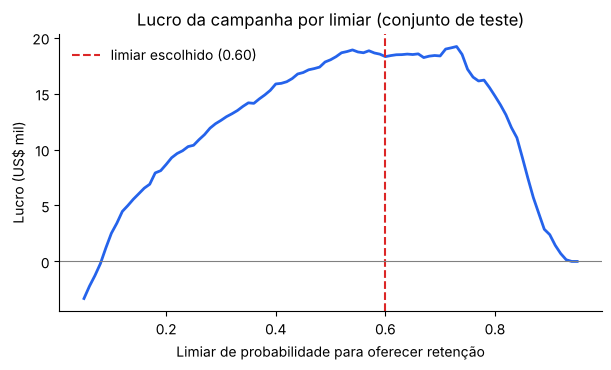

In [9]:
curva = [lucro(y_test, proba, t, mens_test) / 1000 for t in grade]
plt.plot(grade, curva, color=AZUL, linewidth=2)
plt.axvline(limiar, color=VERMELHO, linestyle="--", label=f"limiar escolhido ({limiar:.2f})")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Limiar de probabilidade para oferecer retenção")
plt.ylabel("Lucro (US$ mil)")
plt.title("Lucro da campanha por limiar (conjunto de teste)")
plt.legend(frameon=False)
plt.show()

**Abordar todo mundo dá prejuízo**, porque três em cada quatro clientes não iam sair e a oferta custa dinheiro para todos. O modelo transforma a campanha em lucro ao concentrar as ofertas em cerca de um terço da base.

## 6. O que mais pesa na previsão

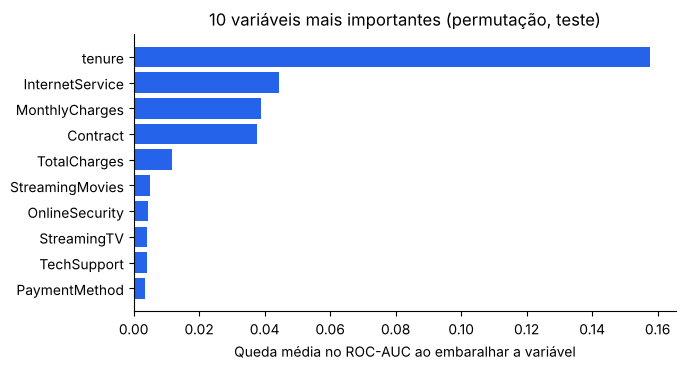

In [10]:
imp = permutation_importance(modelo, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=SEED)
top = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(10)
plt.barh(top.index, top.values, color=AZUL)
plt.xlabel("Queda média no ROC-AUC ao embaralhar a variável")
plt.title("10 variáveis mais importantes (permutação, teste)")
plt.show()

## Conclusões

- Um modelo **simples** (regressão logística) chega a ROC-AUC de cerca de **0,84** no teste e empata com o gradient boosting.
- O que mais muda o resultado não é o algoritmo, e sim **usar o modelo para decidir quem abordar**: a mesma campanha que daria prejuízo oferecida a todos passa a dar lucro.
- Aqui o limiar otimizado (0,60) rende só um pouco mais que o padrão de 0,5, porque o `class_weight="balanced"` já empurra as probabilidades para cima. A curva mostra onde está o risco: com limiares baixos, a campanha volta ao prejuízo. Com outras premissas de custo, o limiar ótimo muda, e é por isso que ele deve ser calculado, e não assumido.
- **Tempo de casa** é o fator mais importante; tipo de internet, valor mensal e contrato vêm em seguida.

**Limitações:** as premissas de custo e de sucesso da oferta são hipóteses. O `class_weight="balanced"` descalibra as probabilidades, e uma calibração (`CalibratedClassifierCV`) seria o próximo passo antes de usar os valores como probabilidades reais.

O modelo servido como API, com testes e Docker, está em **[github.com/juliamunizcarvalh0/previsao-churn](https://github.com/juliamunizcarvalh0/previsao-churn)**.